# Wet AMD Lesion Segmentation — Model 1: Dual-Head U-Net

This notebook implements Model 1 for retinal optical coherence tomography (OCT) lesion segmentation[cite: 1]. 

Building upon the baseline U-Net architecture, this model introduces an auxiliary binary lesion detection branch to assist multi-class segmentation[cite: 1, 2]:
* **Input Resolution:** Preserves the native aspect ratio ($384 \times 576$, matching $380 \times 570$) rather than downscaling to $224 \times 224$, keeping fine lesion boundaries intact[cite: 1, 2].
* **Auxiliary Binary Head:** Predicts a foreground mask ($\text{class} > 0$) to isolate lesion regions from background tissue[cite: 2].
* **Feature Refinement:** Passes binary probability maps through a $7 \times 7$ convolutional block to extract wider spatial context before merging with multi-class decoder features[cite: 2].
* **Joint Multi-Task Loss:** Optimizes both binary detection and multi-class classification simultaneously[cite: 1, 2].

## 1. Setup and Reproducibility
Import dependencies, configure hardware acceleration (CUDA, MPS, or CPU), and set random seeds across PyTorch and NumPy for consistent runs[cite: 1, 2].

In [1]:
import os
import csv
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

def seed_everything(seed: int = 42):
    """Locks random seeds across libraries and backends."""
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    """Ensures deterministic seeding across DataLoader worker subprocesses."""
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

SEED = 42
seed_everything(SEED)

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device}")

Active Compute Device: mps


## 2. Dataset and Preprocessing
Loads pre-sliced OCT B-scans and categorical ground-truth masks from `processed_data/`[cite: 1].

For each sample, the dataset returns:
* A normalized single-channel OCT scan ($1 \times 384 \times 576$)[cite: 1].
* A multi-class categorical mask ($384 \times 576$) with label indices 0 through 5[cite: 1].
* A binary target mask ($1 \times 384 \times 576$) flagging any lesion pixel as 1.0 and background as 0.0[cite: 1, 2].

In [2]:
CLASS_PALETTE_RGB = np.array([
    [0, 0, 0],        # 0: Background
    [255, 0, 0],      # 1: Subretinal Fluid (SRF)
    [0, 255, 0],      # 2: Intraretinal Fluid (IRF)
    [0, 0, 255],      # 3: Pigment Epithelial Detachment (PED)
    [255, 255, 0],    # 4: Subretinal Hyperreflective Material (SHRM)
    [255, 0, 255]     # 5: Ellipsoid Zone (IS/OS)
], dtype=np.int32)

CLASS_NAMES = ["Background", "SRF", "IRF", "PED", "SHRM", "IS/OS"]

class AMDDatasetModel1(Dataset):
    def __init__(self, data_root="processed_data", split="train", target_size=(384, 576)):
        self.inputs_dir = os.path.join(data_root, split, "inputs")
        self.outputs_dir = os.path.join(data_root, split, "outputs")
        self.target_size = target_size

        if not os.path.exists(self.inputs_dir):
            raise FileNotFoundError(f"Input directory not found: {self.inputs_dir}. Ensure data slicing has been executed.")

        self.filenames = sorted([
            f for f in os.listdir(self.inputs_dir)
            if f.endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('.')
        ])

    def __len__(self):
        return len(self.filenames)

    def _rgb_to_class(self, mask_rgb):
        mask = np.ascontiguousarray(mask_rgb, dtype=np.int32)
        dists = np.sum((mask[:, :, None, :] - CLASS_PALETTE_RGB[None, None, :, :]) ** 2, axis=-1)
        return np.argmin(dists, axis=-1)

    def __getitem__(self, idx):
        in_fname = self.filenames[idx]
        img_path = os.path.join(self.inputs_dir, in_fname)
        out_fname = in_fname.replace("_input", "_output") if "_input" in in_fname else in_fname
        mask_path = os.path.join(self.outputs_dir, out_fname)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask_bgr = cv2.imread(mask_path)

        if img is None or mask_bgr is None:
            raise ValueError(f"Corrupt or missing image/mask at index {idx}: {img_path}")

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)

        # Bilinear interpolation for grayscale scan, nearest-neighbor for categorical labels
        img = cv2.resize(img, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_NEAREST)

        mask_labels = self._rgb_to_class(mask_rgb)

        img_tensor = torch.from_numpy(np.ascontiguousarray(img)).unsqueeze(0).float() / 255.0  # (1, H, W)
        mask_tensor = torch.from_numpy(np.ascontiguousarray(mask_labels)).long()                # (H, W)
        
        # Binary target: 1.0 for any lesion biomarker (> 0), 0.0 for background
        binary_target = (mask_tensor > 0).float().unsqueeze(0)                                  # (1, H, W)

        return img_tensor, mask_tensor, binary_target

In [2]:
CLASS_PALETTE_RGB = np.array([
    [0, 0, 0],        # 0: Background
    [255, 0, 0],      # 1: Subretinal Fluid (SRF)
    [0, 255, 0],      # 2: Intraretinal Fluid (IRF)
    [0, 0, 255],      # 3: Pigment Epithelial Detachment (PED)
    [255, 255, 0],    # 4: Subretinal Hyperreflective Material (SHRM)
    [255, 0, 255]     # 5: Ellipsoid Zone (IS/OS)
], dtype=np.int32)

CLASS_NAMES = ["Background", "SRF", "IRF", "PED", "SHRM", "IS/OS"]

class AMDDatasetModel1(Dataset):
    def __init__(self, data_root="processed_data", split="train", target_size=(384, 576)):
        self.inputs_dir = os.path.join(data_root, split, "inputs")
        self.outputs_dir = os.path.join(data_root, split, "outputs")
        self.target_size = target_size

        if not os.path.exists(self.inputs_dir):
            raise FileNotFoundError(f"Input directory not found: {self.inputs_dir}. Ensure data slicing has been executed.")

        self.filenames = sorted([
            f for f in os.listdir(self.inputs_dir)
            if f.endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('.')
        ])

    def __len__(self):
        return len(self.filenames)

    def _rgb_to_class(self, mask_rgb):
        mask = np.ascontiguousarray(mask_rgb, dtype=np.int32)
        dists = np.sum((mask[:, :, None, :] - CLASS_PALETTE_RGB[None, None, :, :]) ** 2, axis=-1)
        return np.argmin(dists, axis=-1)

    def __getitem__(self, idx):
        in_fname = self.filenames[idx]
        img_path = os.path.join(self.inputs_dir, in_fname)
        out_fname = in_fname.replace("_input", "_output") if "_input" in in_fname else in_fname
        mask_path = os.path.join(self.outputs_dir, out_fname)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask_bgr = cv2.imread(mask_path)

        if img is None or mask_bgr is None:
            raise ValueError(f"Corrupt or missing image/mask at index {idx}: {img_path}")

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)

        # Bilinear interpolation for grayscale scan, nearest-neighbor for categorical labels
        img = cv2.resize(img, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_NEAREST)

        mask_labels = self._rgb_to_class(mask_rgb)

        img_tensor = torch.from_numpy(np.ascontiguousarray(img)).unsqueeze(0).float() / 255.0  # (1, H, W)
        mask_tensor = torch.from_numpy(np.ascontiguousarray(mask_labels)).long()                # (H, W)
        
        # Binary target: 1.0 for any lesion biomarker (> 0), 0.0 for background
        binary_target = (mask_tensor > 0).float().unsqueeze(0)                                  # (1, H, W)

        return img_tensor, mask_tensor, binary_target

## 3. Dual-Head U-Net Architecture
Constructs a shared U-Net encoder-decoder with two output branches[cite: 1, 2]:
* **Binary Head:** Outputs single-channel logits predicting overall lesion presence[cite: 2].
* **Refinement Block:** Processes the binary probabilities with a $7 \times 7$ convolution layer to capture regional boundary cues[cite: 2].
* **Multi-Class Head:** Merges the main decoder features with the refined binary cues to classify the 6 individual target classes[cite: 1, 2].

In [3]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class DualHeadUNet(nn.Module):
    def __init__(self, in_channels: int = 1, num_classes: int = 6, base_channels: int = 32):
        super().__init__()
        c = base_channels
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Shared Contracting Encoder
        self.inc = DoubleConv(in_channels, c)          # 1 -> 32
        self.down1 = DoubleConv(c, c * 2)             # 32 -> 64
        self.down2 = DoubleConv(c * 2, c * 4)         # 64 -> 128
        self.down3 = DoubleConv(c * 4, c * 8)         # 128 -> 256
        self.bottleneck = DoubleConv(c * 8, c * 16)   # 256 -> 512

        # Shared Expanding Decoder
        self.up1 = nn.ConvTranspose2d(c * 16, c * 8, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(c * 16, c * 8)

        self.up2 = nn.ConvTranspose2d(c * 8, c * 4, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(c * 8, c * 4)

        self.up3 = nn.ConvTranspose2d(c * 4, c * 2, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(c * 4, c * 2)

        self.up4 = nn.ConvTranspose2d(c * 2, c, kernel_size=2, stride=2)
        self.conv_up4 = DoubleConv(c * 2, c)

        # Head 1: Binary Lesion Segmentation Head
        self.binary_head = nn.Conv2d(c, 1, kernel_size=1)

        # Kernel=7 Refinement Block (Receptive field fusion for binary feature maps)
        self.refine_kernel7 = nn.Sequential(
            nn.Conv2d(1, c, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm2d(c),
            nn.ReLU(inplace=True)
        )

        # Head 2: Multi-Class Segmentation Head
        self.multiclass_head = nn.Sequential(
            DoubleConv(c * 2, c),
            nn.Conv2d(c, num_classes, kernel_size=1)
        )

    def _match_and_cat(self, x_up: torch.Tensor, x_skip: torch.Tensor) -> torch.Tensor:
        if x_up.shape[2:] != x_skip.shape[2:]:
            diff_y = x_skip.size(2) - x_up.size(2)
            diff_x = x_skip.size(3) - x_up.size(3)
            x_up = F.pad(x_up, [diff_x // 2, diff_x - diff_x // 2,
                               diff_y // 2, diff_y - diff_y // 2])
        return torch.cat([x_skip, x_up], dim=1)

    def forward(self, x: torch.Tensor):
        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(self.pool(x1))
        x3 = self.down2(self.pool(x2))
        x4 = self.down3(self.pool(x3))
        m = self.bottleneck(self.pool(x4))

        # Decoder
        d1 = self.conv_up1(self._match_and_cat(self.up1(m), x4))
        d2 = self.conv_up2(self._match_and_cat(self.up2(d1), x3))
        d3 = self.conv_up3(self._match_and_cat(self.up3(d2), x2))
        dec_features = self.conv_up4(self._match_and_cat(self.up4(d3), x1))

        # Auxiliary Binary Detection Branch
        binary_logits = self.binary_head(dec_features)

        # Binary Guidance Fusion
        binary_guidance = self.refine_kernel7(torch.sigmoid(binary_logits))
        fused_features = torch.cat([dec_features, binary_guidance], dim=1)

        # Multi-Class Branch
        mc_logits = self.multiclass_head(fused_features)

        return mc_logits, binary_logits

## 4. Model Sanity Check
Passes a synthetic batch through the network to verify output tensor dimensions, skip connections, and total trainable parameter count.

In [4]:
model_check = DualHeadUNet(in_channels=1, num_classes=6, base_channels=32).to(device)
dummy_input = torch.randn(2, 1, 384, 576, device=device)

with torch.no_grad():
    mc_out, bin_out = model_check(dummy_input)

total_params = sum(p.numel() for p in model_check.parameters() if p.requires_grad)

print(f"Device:                          {device}")
print(f"Input batch shape:               {tuple(dummy_input.shape)}")
print(f"Multi-class logits shape:        {tuple(mc_out.shape)}  (Expected: [2, 6, 384, 576])")
print(f"Binary logits shape:             {tuple(bin_out.shape)}  (Expected: [2, 1, 384, 576])")
print(f"Total trainable parameters:      {total_params:,}")

assert mc_out.shape == (2, 6, 384, 576), "Multi-class shape mismatch!"
assert bin_out.shape == (2, 1, 384, 576), "Binary shape mismatch!"
print("\nDualHeadUNet architecture successfully verified!")

Device:                          mps
Input batch shape:               (2, 1, 384, 576)
Multi-class logits shape:        (2, 6, 384, 576)  (Expected: [2, 6, 384, 576])
Binary logits shape:             (2, 1, 384, 576)  (Expected: [2, 1, 384, 576])
Total trainable parameters:      7,792,071

DualHeadUNet architecture successfully verified!


## 5. Multi-Task Loss and Evaluation Metrics
Defines the joint optimization objective and validation metrics[cite: 1, 2]:
* **Multi-Class Loss:** Combines pixel Cross-Entropy with multi-class Soft Dice over lesion classes 1 to 5 (excluding background)[cite: 1].
* **Binary Loss:** Combines Binary Cross-Entropy with foreground Dice loss to supervise lesion localization[cite: 2].
* **Metrics:** Tracks percentage Dice Similarity Coefficient (DSC) and Intersection over Union (IoU) per lesion category[cite: 1].

In [5]:
class MultiTaskLoss(nn.Module):
    def __init__(self, num_classes: int = 6, binary_weight: float = 0.5, ce_weight: float = 0.5, dice_weight: float = 0.5, smooth: float = 1e-5):
        super().__init__()
        self.num_classes = num_classes
        self.binary_weight = binary_weight
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight
        self.smooth = smooth
        
        self.bce = nn.BCEWithLogitsLoss()
        self.ce = nn.CrossEntropyLoss()

    def forward(self, mc_logits, bin_logits, targets, bin_targets):
        # 1. Multi-Class Loss (Cross-Entropy + Foreground Soft Dice on classes 1..5)
        ce_loss = self.ce(mc_logits, targets)
        probs = F.softmax(mc_logits, dim=1)
        targets_one_hot = F.one_hot(targets, num_classes=self.num_classes).permute(0, 3, 1, 2).float()

        dice_total = 0.0
        for c in range(1, self.num_classes):
            p = probs[:, c, ...].contiguous().view(-1)
            t = targets_one_hot[:, c, ...].contiguous().view(-1)
            intersection = (p * t).sum()
            dice = (2.0 * intersection + self.smooth) / (p.sum() + t.sum() + self.smooth)
            dice_total += (1.0 - dice)
        mc_dice_loss = dice_total / (self.num_classes - 1)
        l_mc = (self.ce_weight * ce_loss) + (self.dice_weight * mc_dice_loss)

        # 2. Binary Detection Loss (BCE + Binary Dice)
        bce_loss = self.bce(bin_logits, bin_targets)
        b_probs = torch.sigmoid(bin_logits).view(-1)
        b_targets = bin_targets.view(-1)
        b_intersection = (b_probs * b_targets).sum()
        b_dice_loss = 1.0 - (2.0 * b_intersection + self.smooth) / (b_probs.sum() + b_targets.sum() + self.smooth)
        l_bin = (0.5 * bce_loss) + (0.5 * b_dice_loss)

        # Joint Multi-Task Objective
        total_loss = l_mc + (self.binary_weight * l_bin)
        return total_loss, l_mc, l_bin


def calculate_metrics(preds: torch.Tensor, targets: torch.Tensor, smooth: float = 1e-5):
    class_map = {1: "SRF", 2: "IRF", 3: "PED", 4: "SHRM", 5: "IS/OS"}
    dice_scores, iou_scores = {}, {}

    for cls_idx, cls_name in class_map.items():
        p_mask = (preds == cls_idx).float()
        t_mask = (targets == cls_idx).float()

        intersection = (p_mask * t_mask).sum().item()
        total_p = p_mask.sum().item()
        total_t = t_mask.sum().item()
        union = total_p + total_t - intersection

        dice = (2.0 * intersection + smooth) / (total_p + total_t + smooth) * 100.0
        iou = (intersection + smooth) / (union + smooth) * 100.0

        dice_scores[cls_name] = dice
        iou_scores[cls_name] = iou

    return dice_scores, iou_scores

## 6. Model Training and Checkpointing
Trains the network using AdamW and Cosine Annealing learning rate scheduling[cite: 1]. 

Model weights are saved whenever validation Mean Dice reaches a new peak, and each saved checkpoint is logged to `checkpoints.txt`[cite: 1, 2].

In [6]:
def run_model1_training():
    seed_everything(SEED)
    g = torch.Generator().manual_seed(SEED)

    DATA_DIR = "processed_data"
    BATCH_SIZE = 4
    EPOCHS = 35
    LEARNING_RATE = 1e-4
    NUM_CLASSES = 6
    LOG_FILE = "model1_training_log.csv"
    CHECKPOINT_FILE = "best_model1_dualhead.pth"

    train_dataset = AMDDatasetModel1(DATA_DIR, split="train")
    val_dataset = AMDDatasetModel1(DATA_DIR, split="val")

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=(2 if device.type == "cuda" else 0),
        pin_memory=(device.type == "cuda"),
        worker_init_fn=seed_worker,
        generator=g
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=(2 if device.type == "cuda" else 0),
        pin_memory=(device.type == "cuda")
    )

    print(f"Loaded {len(train_dataset)} training scans and {len(val_dataset)} validation scans.")

    model = DualHeadUNet(in_channels=1, num_classes=NUM_CLASSES, base_channels=32).to(device)
    criterion = MultiTaskLoss(num_classes=NUM_CLASSES, binary_weight=0.5).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    fieldnames = [
        "epoch", "train_loss", "val_loss", "mean_dice", "mean_iou",
        "SRF_dice", "IRF_dice", "PED_dice", "SHRM_dice", "IS_OS_dice",
        "SRF_iou", "IRF_iou", "PED_iou", "SHRM_iou", "IS_OS_iou"
    ]
    with open(LOG_FILE, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

    best_mean_dice = 0.0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss_accum = 0.0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]")
        for images, mc_targets, bin_targets in pbar:
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)
            bin_targets = bin_targets.to(device, dtype=torch.float32)

            optimizer.zero_grad()
            mc_logits, bin_logits = model(images)
            loss, l_mc, l_bin = criterion(mc_logits, bin_logits, mc_targets, bin_targets)
            loss.backward()
            optimizer.step()

            train_loss_accum += loss.item()
            pbar.set_postfix({"loss": f"{loss.item():.4f}", "mc": f"{l_mc.item():.3f}", "bin": f"{l_bin.item():.3f}"})

        scheduler.step()
        epoch_train_loss = train_loss_accum / len(train_loader)

        # Validation Phase
        model.eval()
        val_loss_accum = 0.0
        val_dice_accum = {"SRF": 0.0, "IRF": 0.0, "PED": 0.0, "SHRM": 0.0, "IS/OS": 0.0}
        val_iou_accum  = {"SRF": 0.0, "IRF": 0.0, "PED": 0.0, "SHRM": 0.0, "IS/OS": 0.0}
        val_batches = 0

        with torch.no_grad():
            for images, mc_targets, bin_targets in tqdm(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Val]"):
                images = images.to(device)
                mc_targets = mc_targets.to(device, dtype=torch.long)
                bin_targets = bin_targets.to(device, dtype=torch.float32)

                mc_logits, bin_logits = model(images)
                loss, _, _ = criterion(mc_logits, bin_logits, mc_targets, bin_targets)
                val_loss_accum += loss.item()

                preds = torch.argmax(mc_logits, dim=1)
                d_scores, i_scores = calculate_metrics(preds, mc_targets)

                for k in val_dice_accum:
                    val_dice_accum[k] += d_scores[k]
                    val_iou_accum[k] += i_scores[k]
                val_batches += 1

        epoch_val_loss = val_loss_accum / val_batches
        avg_dice = {k: v / val_batches for k, v in val_dice_accum.items()}
        avg_iou = {k: v / val_batches for k, v in val_iou_accum.items()}
        mean_dice = sum(avg_dice.values()) / len(avg_dice)
        mean_iou = sum(avg_iou.values()) / len(avg_iou)

        print(f"\n--- Epoch {epoch:02d} Summary ---")
        print(f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
        print(f"Mean Dice:  {mean_dice:.2f}% | Mean IoU: {mean_iou:.2f}%")
        print(f"Dice -> SRF: {avg_dice['SRF']:.2f}% | IRF: {avg_dice['IRF']:.2f}% | "
              f"PED: {avg_dice['PED']:.2f}% | SHRM: {avg_dice['SHRM']:.2f}% | IS/OS: {avg_dice['IS/OS']:.2f}%")

        # Log metrics to CSV
        with open(LOG_FILE, "a", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writerow({
                "epoch": epoch,
                "train_loss": f"{epoch_train_loss:.4f}",
                "val_loss": f"{epoch_val_loss:.4f}",
                "mean_dice": f"{mean_dice:.2f}",
                "mean_iou": f"{mean_iou:.2f}",
                "SRF_dice": f"{avg_dice['SRF']:.2f}",
                "IRF_dice": f"{avg_dice['IRF']:.2f}",
                "PED_dice": f"{avg_dice['PED']:.2f}",
                "SHRM_dice": f"{avg_dice['SHRM']:.2f}",
                "IS_OS_dice": f"{avg_dice['IS/OS']:.2f}",
                "SRF_iou": f"{avg_iou['SRF']:.2f}",
                "IRF_iou": f"{avg_iou['IRF']:.2f}",
                "PED_iou": f"{avg_iou['PED']:.2f}",
                "SHRM_iou": f"{avg_iou['SHRM']:.2f}",
                "IS_OS_iou": f"{avg_iou['IS/OS']:.2f}"
            })

        # Save Best Model Checkpoint and record to checkpoints.txt (Meeting Directive)
        if mean_dice > best_mean_dice:
            best_mean_dice = mean_dice
            torch.save(model.state_dict(), CHECKPOINT_FILE)
            with open("checkpoints.txt", "a") as f_ckpt:
                f_ckpt.write(f"Model1 | Epoch {epoch:02d} | Val Mean Dice: {best_mean_dice:.2f}% | Path: {CHECKPOINT_FILE}\n")

    print(f"\nTraining complete. Peak Validation Mean Dice: {best_mean_dice:.2f}%")

# Execute training
run_model1_training()

Loaded 2346 training scans and 703 validation scans.


Epoch 01/35 [Train]:   0%|          | 0/587 [00:00<?, ?it/s]

Epoch 01/35 [Val]:   0%|          | 0/176 [00:00<?, ?it/s]


--- Epoch 01 Summary ---
Train Loss: 1.1887 | Val Loss: 0.9810
Mean Dice:  45.79% | Mean IoU: 38.93%
Dice -> SRF: 43.43% | IRF: 65.91% | PED: 18.96% | SHRM: 36.26% | IS/OS: 64.42%


Epoch 02/35 [Train]:   0%|          | 0/587 [00:00<?, ?it/s]

...

Epoch 34/35 [Val]:   0%|          | 0/176 [00:00<?, ?it/s]


--- Epoch 34 Summary ---
Train Loss: 0.1290 | Val Loss: 0.3821
Mean Dice:  66.51% | Mean IoU: 58.83%
Dice -> SRF: 65.09% | IRF: 76.94% | PED: 56.11% | SHRM: 59.01% | IS/OS: 75.40%


Epoch 35/35 [Train]:   0%|          | 0/587 [00:00<?, ?it/s]

Epoch 35/35 [Val]:   0%|          | 0/176 [00:00<?, ?it/s]


--- Epoch 35 Summary ---
Train Loss: 0.1279 | Val Loss: 0.3824
Mean Dice:  66.60% | Mean IoU: 58.89%
Dice -> SRF: 65.03% | IRF: 78.01% | PED: 56.05% | SHRM: 58.67% | IS/OS: 75.24%

Training complete. Peak Validation Mean Dice: 67.26%


## 7. Training and Validation Curves
Plots loss convergence and per-class validation Dice scores across epochs from `model1_training_log.csv`.

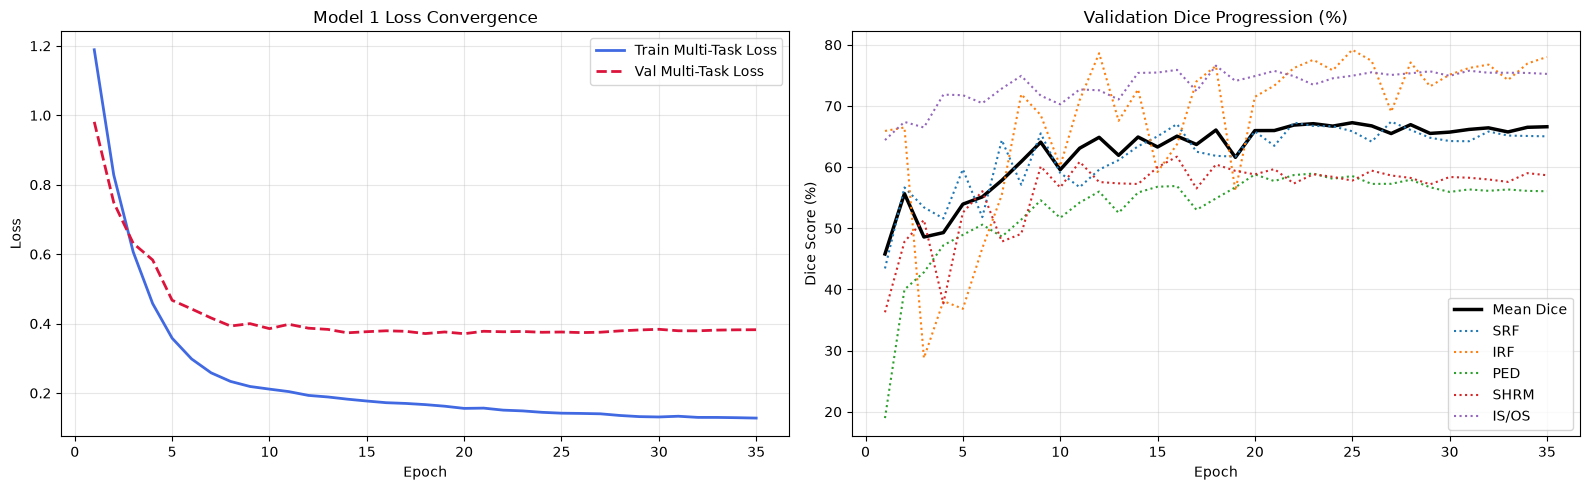

In [7]:
if os.path.exists("model1_training_log.csv"):
    df_log = pd.read_csv("model1_training_log.csv")

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Loss trajectories
    axes[0].plot(df_log["epoch"], df_log["train_loss"], label="Train Multi-Task Loss", color="royalblue", lw=2)
    axes[0].plot(df_log["epoch"], df_log["val_loss"], label="Val Multi-Task Loss", color="crimson", lw=2, linestyle="--")
    axes[0].set_title("Model 1 Loss Convergence")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    # Per-class Dice progression
    axes[1].plot(df_log["epoch"], df_log["mean_dice"], label="Mean Dice", color="black", lw=2.5)
    axes[1].plot(df_log["epoch"], df_log["SRF_dice"], label="SRF", lw=1.5, linestyle=":")
    axes[1].plot(df_log["epoch"], df_log["IRF_dice"], label="IRF", lw=1.5, linestyle=":")
    axes[1].plot(df_log["epoch"], df_log["PED_dice"], label="PED", lw=1.5, linestyle=":")
    axes[1].plot(df_log["epoch"], df_log["SHRM_dice"], label="SHRM", lw=1.5, linestyle=":")
    axes[1].plot(df_log["epoch"], df_log["IS_OS_dice"], label="IS/OS", lw=1.5, linestyle=":")
    axes[1].set_title("Validation Dice Progression (%)")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Dice Score (%)")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()
else:
    print("model1_training_log.csv not found.")

## 8. Validation Benchmark vs. Baseline
Evaluates the best checkpoint on the 703 validation scans and compares scores directly against the baseline replication and published AMD-SD benchmark results[cite: 1, 2].

In [8]:
def evaluate_model1_benchmark():
    checkpoint_path = "best_model1_dualhead.pth"
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"Checkpoint '{checkpoint_path}' not found. Run training first.")

    val_dataset = AMDDatasetModel1("processed_data", split="val")
    val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0)

    model = DualHeadUNet(in_channels=1, num_classes=6, base_channels=32).to(device)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()

    val_dice_accum = {"SRF": 0.0, "IRF": 0.0, "PED": 0.0, "SHRM": 0.0, "IS/OS": 0.0}
    val_iou_accum  = {"SRF": 0.0, "IRF": 0.0, "PED": 0.0, "SHRM": 0.0, "IS/OS": 0.0}
    total_batches = 0

    with torch.no_grad():
        for images, mc_targets, _ in tqdm(val_loader, desc="Evaluating Model 1"):
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)

            mc_logits, _ = model(images)
            preds = torch.argmax(mc_logits, dim=1)

            d_scores, i_scores = calculate_metrics(preds, mc_targets)
            for k in val_dice_accum:
                val_dice_accum[k] += d_scores[k]
                val_iou_accum[k] += i_scores[k]
            total_batches += 1

    m1_dice = {k: v / total_batches for k, v in val_dice_accum.items()}
    m1_iou  = {k: v / total_batches for k, v in val_iou_accum.items()}
    m1_mean_dice = sum(m1_dice.values()) / len(m1_dice)
    m1_mean_iou = sum(m1_iou.values()) / len(m1_iou)

    # Reference values from Table 3 in the paper and your baseline run
    paper_dice = {"SRF": 78.65, "IRF": 78.66, "PED": 79.62, "SHRM": 72.04, "IS/OS": 83.76, "Mean": 78.55}
    base_dice  = {"SRF": 66.13, "IRF": 78.10, "PED": 55.59, "SHRM": 58.42, "IS/OS": 75.08, "Mean": 66.66}

    benchmark_df = pd.DataFrame({
        "Lesion Class": ["SRF", "IRF", "PED", "SHRM", "IS/OS", "Mean Average"],
        "Paper U-Net Dice (%)": [paper_dice["SRF"], paper_dice["IRF"], paper_dice["PED"], paper_dice["SHRM"], paper_dice["IS/OS"], paper_dice["Mean"]],
        "Baseline Dice (%)":    [base_dice["SRF"], base_dice["IRF"], base_dice["PED"], base_dice["SHRM"], base_dice["IS/OS"], base_dice["Mean"]],
        "Model 1 Dice (%)": [
            round(m1_dice["SRF"], 2), round(m1_dice["IRF"], 2), round(m1_dice["PED"], 2),
            round(m1_dice["SHRM"], 2), round(m1_dice["IS/OS"], 2), round(m1_mean_dice, 2)
        ],
        "Model 1 IoU (%)": [
            round(m1_iou["SRF"], 2), round(m1_iou["IRF"], 2), round(m1_iou["PED"], 2),
            round(m1_iou["SHRM"], 2), round(m1_iou["IS/OS"], 2), round(m1_mean_iou, 2)
        ]
    })

    print("\n" + "="*85)
    print("MODEL 1 DUAL-HEAD EVALUATION vs. BASELINE & PAPER BENCHMARK")
    print("="*85)
    print(benchmark_df.to_string(index=False))
    benchmark_df.to_csv("model1_benchmark_report.csv", index=False)
    print("\nReport saved to 'model1_benchmark_report.csv'.")
    return benchmark_df

df_res = evaluate_model1_benchmark()

Evaluating Model 1:   0%|          | 0/176 [00:00<?, ?it/s]


MODEL 1 DUAL-HEAD EVALUATION vs. BASELINE & PAPER BENCHMARK
Lesion Class  Paper U-Net Dice (%)  Baseline Dice (%)  Model 1 Dice (%)  Model 1 IoU (%)
         SRF                 78.65              66.13             65.86            58.73
         IRF                 78.66              78.10             79.19            75.35
         PED                 79.62              55.59             58.54            48.99
        SHRM                 72.04              58.42             57.79            49.35
       IS/OS                 83.76              75.08             74.94            64.91
Mean Average                 78.55              66.66             67.26            59.47

Report saved to 'model1_benchmark_report.csv'.


## 9. Qualitative Predictions
Displays sample validation scans side-by-side with ground-truth masks, Model 1 multi-class predictions, and auxiliary binary lesion heatmaps[cite: 1, 2].

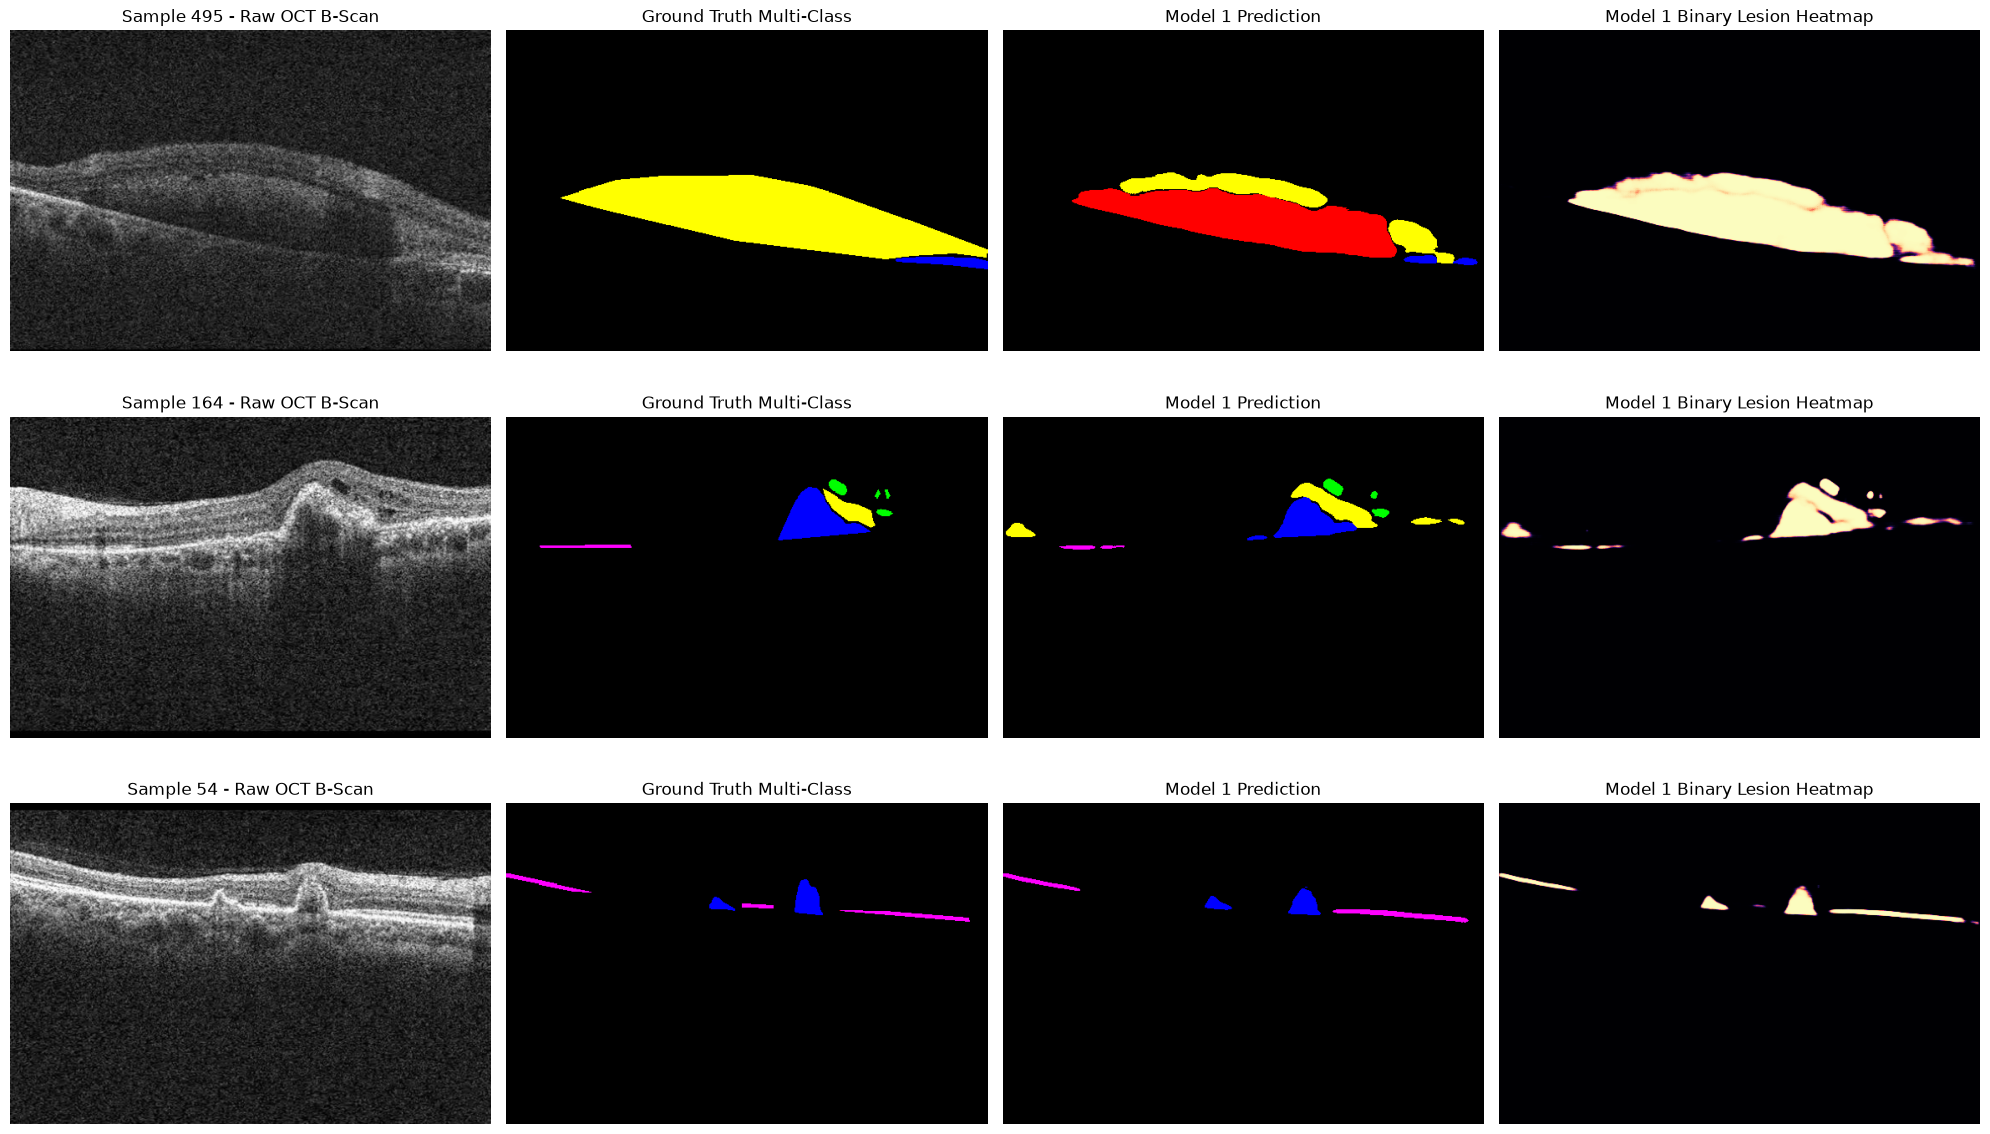

In [9]:
def decode_class_mask_to_rgb(mask_idx: np.ndarray) -> np.ndarray:
    h, w = mask_idx.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for c_id, color in enumerate(CLASS_PALETTE_RGB):
        rgb[mask_idx == c_id] = color
    return rgb

def visualize_model1_predictions(num_samples: int = 3):
    val_dataset = AMDDatasetModel1("processed_data", split="val")
    model = DualHeadUNet(in_channels=1, num_classes=6, base_channels=32).to(device)
    model.load_state_dict(torch.load("best_model1_dualhead.pth", map_location=device))
    model.eval()

    indices = np.random.choice(len(val_dataset), size=num_samples, replace=False)
    fig, axes = plt.subplots(num_samples, 4, figsize=(20, 4 * num_samples))

    with torch.no_grad():
        for row, idx in enumerate(indices):
            img_tensor, mask_tensor, bin_tensor = val_dataset[idx]
            inp = img_tensor.unsqueeze(0).to(device)

            mc_logits, bin_logits = model(inp)
            pred_mc = torch.argmax(mc_logits, dim=1).squeeze(0).cpu().numpy()
            pred_bin = torch.sigmoid(bin_logits).squeeze().cpu().numpy()

            scan_np = img_tensor.squeeze().cpu().numpy()
            gt_rgb = decode_class_mask_to_rgb(mask_tensor.numpy())
            pred_rgb = decode_class_mask_to_rgb(pred_mc)

            # 1. Raw OCT Scan
            axes[row, 0].imshow(scan_np, cmap="gray")
            axes[row, 0].set_title(f"Sample {idx} - Raw OCT B-Scan")
            axes[row, 0].axis("off")

            # 2. Multi-class Ground Truth
            axes[row, 1].imshow(gt_rgb)
            axes[row, 1].set_title("Ground Truth Multi-Class")
            axes[row, 1].axis("off")

            # 3. Model 1 Multi-class Prediction
            axes[row, 2].imshow(pred_rgb)
            axes[row, 2].set_title("Model 1 Prediction")
            axes[row, 2].axis("off")

            # 4. Binary Lesion Guidance Heatmap
            im_bin = axes[row, 3].imshow(pred_bin, cmap="magma", vmin=0.0, vmax=1.0)
            axes[row, 3].set_title("Model 1 Binary Lesion Heatmap")
            axes[row, 3].axis("off")

    plt.tight_layout()
    plt.show()

visualize_model1_predictions(num_samples=3)